- **定义**：节点的下游候选节点 **在图编译阶段就完全确定**，只是运行时根据条件选择哪条边执行。
- 特点：
  - 下游节点集合固定，数量、目标在编译时确定
  - 运行时可选择**一个或多个**下游目标
  - 可以用来做条件分支，但不生成新的节点

⚡ 核心判断：

> **编译期知道下游集合 → 静态分支**
### 1. 并行节点
并行节点是最简单的静态分支形式。当多个节点都从同一个上游节点触发时，它们会在同一个**超步**被激活。

{'topic': '猫咪', 'poem': '《题猫》\n狸奴憨卧竹阴凉，扑蝶攀枝野趣长。\n忽瞪圆瞳竖耳望，缘何今夜不抓老鼠只抓光。\n\n注：我的仿写创作思路是抓住猫咪的灵动与慵懒双重特性。首句“憨卧竹阴”表现其慵懒，次句“扑蝶攀枝”则显顽皮。转句“瞪瞳竖耳”刻画警觉神态，结句以“不抓老鼠只抓光”的幽默转折，既呼应前文野趣，又暗含对现代家猫习性的观察，使全诗谐趣横生。', 'joke': '一只猫在追一只老鼠，老鼠钻进了洞里。猫等了半天，老鼠不出来，于是猫学狗叫：“汪汪！”老鼠吓得立刻窜了出来。猫一把抓住老鼠，得意地说：“小样儿，不会外语还敢出来混？”'}


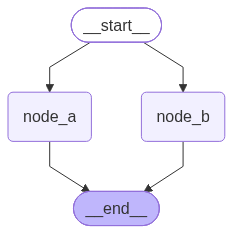

In [10]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage
from IPython.display import display

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke(
        [
            HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")
        ]
    ).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke(
        [
            HumanMessage(f"写一个关于 {state['topic']} 的笑话")
        ]
    ).content
    return {
        "joke": joke
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
## 以下两个构成并行节点
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"topic": "猫咪"})
print(res)
display(graph)

### 2. 条件分支
**`StateGraph`** 提供了 **`add_conditional_edges`** 方法，用于从某个上游节点出发，根据运行时状态选择下游节点。

2.1. 不使用 `path_map`

==============================  -> poem_res <-  ==============================
{'topic': '布偶狗', 'content_type': '诗', 'poem': '《布偶狗》\n绒毛乖巧伴娇娃，憨态可掬披彩纱。\n慧眼识得真善美，忠诚守护乐无涯。\n\n赏析：这首作品以布偶狗为题材，通过“绒毛乖巧”、“憨态可掬”等生动描绘，展现其可爱形象。后两句“慧眼识得真善美，忠诚守护乐无涯”，巧妙赋予布偶狗灵性，表达其识别真善美、忠诚守护的品质，既体现了对布偶狗的喜爱，又寄寓了美好寓意。'}
==============================  -> joke_res <-  ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'joke': '## 布偶狗的笑话\n\n小明家的布偶狗“棉花”特别粘人，走哪儿跟哪儿，像块甩不掉的棉花糖。\n\n一天，小明下班回家，累得瘫在沙发上。棉花立刻跳上来，一屁股坐在他肚子上，拿脑袋使劲拱他下巴，尾巴摇得像螺旋桨。\n\n小明有气无力地说：“棉花，我今天好累，让我安静躺会儿行不？”\n\n棉花歪头看了他两秒，突然张嘴叼起他的拖鞋，哒哒哒跑到门口，回头冲他“汪汪”两声。\n\n小明懵了：“你叼我鞋干嘛？”\n\n棉花急了，又跑回来，用爪子扒拉他的手，再跑到门口趴下，眼神拼命暗示。\n\n小明恍然大悟：“哦——你是想让我穿鞋出门遛你？”\n\n棉花疯狂摇尾巴，扑上来舔了他一脸口水。\n\n小明叹了口气，一边穿鞋一边嘟囔：“到底你是狗，还是我是狗？怎么感觉每天在被一只毛绒玩具遛呢……”\n\n刚打开门，棉花“噌”地窜出去，结果一头撞上了门框——因为太毛茸茸，缓冲了一下，弹回来原地转了三圈，然后若无其事地回头看他，表情仿佛在说：“……看什么看，我故意的。”'}


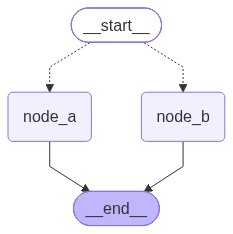

In [2]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from IPython.display import display
from dotenv import load_dotenv

load_dotenv(override=True)

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = deepseek_model.invoke(
        [HumanMessage(content=f"写一首关于 {state['topic']}的七言绝句")]
    ).content
    return {
        "poem": poem,
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = deepseek_model.invoke(
        [HumanMessage(content=f"写一个关于 {state['topic']}的笑话")]
    ).content
    return {
        "joke": joke,
    }

def router(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "node_a"
    return "node_b"

builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
# 关键语句：add_conditional_edges
builder.add_conditional_edges(START, router)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, ' -> poem_res <- ', '=' * 30)
print(poem_res)
print('=' * 30, ' -> joke_res <- ', '=' * 30)
print(joke_res)

display(graph)


2.2 使用 `path_map`

============================== -> poem_res <- ==============================
{'topic': '布偶狗', 'content_type': '诗', 'poem': '《布偶狗》\n绒团乖巧卧怀柔，慧眼晶莹解客愁。\n稚子牵绳学步走，一庭春色共悠悠。\n\n赏析：这首作品以布偶狗为题，通过“绒团乖巧”形象描绘其可爱形态，“慧眼晶莹”拟人化展现其善解人意。后两句转写稚子牵绳学步的生动场景，将布偶狗与孩童、春色融为一体，以“共悠悠”收束，既表现宠物伴人成长之趣，又暗含春光与人情交融的温馨意境。'}
============================== -> joke_res <- ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'joke': '## 布偶狗\n\n邻居家养了只布偶猫，天天在朋友圈晒。我嘴馋，也想要一只，但老婆对猫毛过敏，只好作罢。\n\n昨天逛夜市，看见个摊子卖“布偶狗”，毛茸茸一团趴在笼子里，标签写着：“不掉毛、不拆家、会装死。”我眼睛一亮，这不就是为我量身定制的吗？当场掏钱抱回家。\n\n到家往沙发上一扔，它果然一动不动，完美。老婆回来摸了半天，夸我总算买了件正常东西。\n\n晚上看电视，我想显摆一下，冲它喊：“握手！”没反应。我又喊：“坐下！”还是没反应。我急了，一脚踢过去：“装死！”它咕噜滚到地上，继续不动。\n\n老婆斜我一眼：“你买的是个毛绒玩具吧？”我嘴硬：“这是高冷型布偶狗，得用爱感化。”\n\n于是接下来三天，我给它喂饭、梳毛、讲睡前故事，它始终维持着同一个姿势——面朝下趴着，屁股撅着，像一只放弃狗生的咸鱼。\n\n第四天我崩溃了，拎着它去找夜市摊主。摊主正忙着，头也不抬：“退货？行，给你换一只。”说着从身后箱子里又掏出一只一模一样的。\n\n我急了：“这不还是玩具吗？！”\n\n摊主把狗翻过来，指着肚皮上一行小字：“你看清楚，我们这是正品‘布偶狗’——布做的偶，狗的造型。明码标价，童叟无欺。旁边那只贵二十，是升级版，会叫。”\n\n我低头一看，果然，标签底下还有行蚂蚁大的字：“温馨提示：如遇不叫，请用力拍打。”\n\n摊主补充：“拍坏了包换。”\n\n我抱

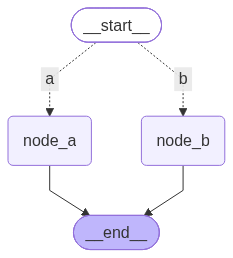

In [3]:
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv
from IPython.display import display

load_dotenv(override=True)

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = deepseek_model.invoke(
        [HumanMessage(content=f"写一首关于{state['topic']}的七言绝句")]
    ).content
    return {
        "poem": poem,
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = deepseek_model.invoke(
        [HumanMessage(content=f"写一个关于{state['topic']}的笑话")]
    ).content
    return {
        "joke": joke,
    }

def router(state: OverAllState) -> Literal["a", "b"]:
    if "诗" in state["content_type"]:
        return "a"
    return "b"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_conditional_edges(
    START,
    router,
    # 使用path_map
    path_map={
        "a": "node_a",
        "b": "node_b",
    }
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

display(graph)

 2.3 同时路由至多个节点

**`add_conditional_edges`** 也支持一次路由到多个下游节点。

2.3.1 不用path_map

==============================  -> poem_res <-  ==============================
{'topic': '布偶狗', 'content_type': '诗', 'poem': '《布偶狗》\n绒团乖巧卧膝头，慧眼晶莹解客愁。\n长耳垂云听夜雨，春风绕指更温柔。\n\n赏析：这首作品以布偶狗为题，通过“绒团”、“慧眼”、“长耳”等意象生动勾勒其可爱形态。后两句“长耳垂云听夜雨，春风绕指更温柔”巧妙运用拟人手法，赋予布偶狗灵性，既展现其陪伴解忧的温馨场景，又暗含主人对它的无限怜爱，语言凝练而意境深远。', 'ci_poem': '## 布偶狗\n\n绒毛软塌塌地垂着，像一朵落在地上的云。两只黑豆眼空洞又深情，缝上去的，取不下来。耳朵耷拉着，听不见主人回来，也不听见主人走。\n\n我抱它，它就软在我怀里。像一团有重量的棉花，有温度的那种——假的温度，从暖气片上蹭来的。它的鼻子是深棕色布头，被摸得起了毛球。嘴巴是一条线，弯的，笑的模样，出厂就定好了的。我骂它，它笑；我走了三天，回来它还是笑。\n\n有一天我发现它肚皮上开了一道线。棉花往外挤，白花花的，像它憋了很久想说点什么。我拿针缝上了。缝的时候它看着我——不对，它没看我，它看的是所有方向。\n\n后来我不抱它了。把它搁在窗台上，让它看外头的狗跑来跑去。真的狗会叫，会甩水，会追自己的尾巴。布偶狗只会坐着，慢慢积灰。\n\n我有时候觉得它在等什么。等我想起来再抱它一次？还是等棉花彻底塌下去，自己变成一块布？\n\n它没告诉我。它嘴巴那条线，一直是弯的。'}
==============================  -> joke_res <-  ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'ci_poem': '## 布偶狗\n\n绒毛软塌塌地垂着\n像被雨淋湿的云\n两颗纽扣眼睛\n缝得太紧\n看不见我藏在掌心的\n半块饼干\n\n你总是歪着头\n假装听不懂\n“握手”这个词\n却在我转身时\n用棉花做的尾巴\n扫落桌上\n第三颗星星\n\n他们会把你塞进洗衣机\n甩干、晾晒、拍打\n我就躲在门后\n数你掉落的绒毛\n一根、两根\n足够织成\n通往月

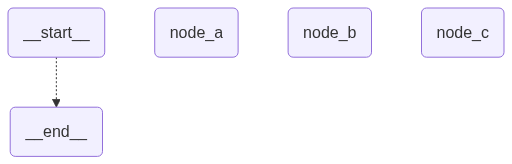

In [4]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from IPython.display import display
from dotenv import load_dotenv

load_dotenv(override=True)

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = deepseek_model.invoke(
        [HumanMessage(content=f"写一首关于 {state['topic']}的七言绝句")]
    ).content
    return {
        "poem": poem,
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = deepseek_model.invoke(
        [HumanMessage(content=f"写一个关于 {state['topic']}的笑话")]
    ).content
    return {
        "joke": joke,
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = deepseek_model.invoke(
        [HumanMessage(content=f"写一个关于 {state['topic']}的词")]
    ).content
    return {
        "ci_poem": ci_poem,
    }

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    return ["node_b", "node_c"]

builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
# 没使用path_map
builder.add_conditional_edges(START, router)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, ' -> poem_res <- ', '=' * 30)
print(poem_res)
print('=' * 30, ' -> joke_res <- ', '=' * 30)
print(joke_res)

display(graph)

2.3.2 通过 **`path_map`** 显示声明映射关系

==============================  -> poem_res <-  ==============================


{
    'topic': '布偶狗',
    'content_type': '诗',
    'poem': 
'《布偶狗》\n绒毛软塌似云团，稚气憨姿惹人怜。\n慧黠眸含春水暖，绒尾摇欢绕膝前。\n\n注：我的创作思路是抓住布偶狗柔软
可爱的外形与活泼聪慧的性情。首句以“云团”喻其蓬松毛发，次句“憨姿”写其稚拙之态，第三句“春水”拟其温润眼神，尾句“绕膝”
动态展现亲近之态。通过视觉触觉转换与拟人手法，传递布偶狗带来的温暖陪伴感。',
    'ci_poem': '## 布偶狗\n\n绒毛松软似云堆，  \n玻璃眼珠映斜晖。  \n终日蜷伏沙发角，  \n等人抱起不肯归。  
\n\n耳垂布缝微微晃，  \n尾巴线缀轻轻垂。  \n莫笑无声少机灵，  \n一颗痴心等你回。'
}

==============================  -> joke_res <-  ==============================


{
    'topic': '布偶狗',
    'content_type': '笑话',
    'ci_poem': '## 
布偶狗\n\n绒毛塌陷，棉花心肠，\n你伏在沙发凹陷的中央，\n像一句被说了一半的谎。\n\n纽扣眼睛，看穿我假装\n没注意你偷
吃月光的模样——\n线头嘴角，还挂着半片夕阳。\n\n我拆开你，又缝上，\n把心跳塞进你空荡的胸腔。\n从此你替我摇尾巴，\n在
每一个我沉默的晚上。\n\n布偶狗，布偶狗，\n你是我缝歪了的那道伤口，\n不疼，但总在换季时发痒。\n\n我抱着你，像抱着\n
一个不会长大的自己——\n棉花做的勇敢，绒毛做的忧伤。',
    'joke': 
'有一天，一只布偶狗被主人放在沙发上就出门了。\n\n小偷撬门进来，翻箱倒柜，一抬头看见沙发上坐着一只狗，吓得腿都软了。
\n\n他试探着问：“你……你会叫吗？”\n\n布偶狗一动不动，用纽扣眼睛深情地望着他。\n\n小偷松了口气：“原来是假的。” 
于是放心大胆地继续翻。\n\n这时布偶狗突然开口了：“你翻归翻，别动我骨头玩具。”\n\n小偷当场瘫倒在地，连滚带爬地跑了。\
n\n主人回来后听邻居说了这事，纳闷地问布偶狗：“你什么时候会说话的？”\n\n布偶狗眨了眨纽扣眼：“我没说话啊，是沙发底下
那只真狗说的——它嫌小偷踩到它尾巴了。”'
}

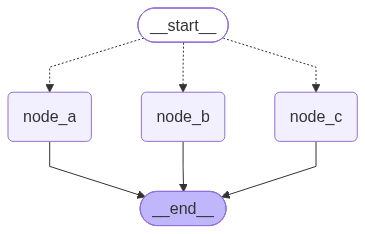

In [9]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from IPython.display import display
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = deepseek_model.invoke(
        [HumanMessage(content=f"写一首关于 {state['topic']}的七言绝句")]
    ).content
    return {
        "poem": poem,
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = deepseek_model.invoke(
        [HumanMessage(content=f"写一个关于 {state['topic']}的笑话")]
    ).content
    return {
        "joke": joke,
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = deepseek_model.invoke(
        [HumanMessage(content=f"写一个关于 {state['topic']}的词")]
    ).content
    return {
        "ci_poem": ci_poem,
    }

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    return ["node_b", "node_c"]

builder = StateGraph(state_schema=OverAllState)

builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_conditional_edges(
    START,
    router,
    # 使用了path_map来添加映射
    path_map={
        "node_a": "node_a",
        "node_b": "node_b",
        "node_c": "node_c",
    }
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, ' -> poem_res <- ', '=' * 30)
rprint(poem_res)
print('=' * 30, ' -> joke_res <- ', '=' * 30)
rprint(joke_res)

display(graph)

### 3. defer node execution
某些情况下，我们希望在所有常规任务节点执行完毕后，再进行日志、审计等收尾工作。此时可以在添加节点时设置**`defer=True`**

**`defer=True`** 的含义是：

当前节点不会在其被触发后立即执行，而是被延迟到常规图运行流程结束后，再在**额外的超步中**触发执行。

2026-10-18 18:46:58.749 | INFO     | __main__:audit_node:39 - 任务节点全部执行完毕，诗已生成，笑话已生成


{
    'topic': '布偶狗',
    'poem': 
'《布偶狗》\n绒身俏坐碧茵丛，长耳垂肩目点瞳。\n偶被风惊歪首望，疑春藏入绣球中。\n\n赏析：这首作品以布偶狗为题材，通
过“绒身俏坐”、“长耳垂肩”等生动描绘，展现其可爱形象。后两句巧妙运用拟人手法，写布偶狗被风惊动歪头张望，疑心春天藏入
绣球花中，既富童趣又暗合布偶狗的静物特性，形成含蓄隽永的意境。',
    'joke': '## 
布偶狗的笑话\n\n我妈买了一只布偶狗，毛茸茸的，跟真的似的。她特别喜欢，天天抱着看电视。\n\n有一天，邻居来串门，看见
我妈怀里那只“狗”，夸了一句：“这狗真乖，一动不动。”\n\n我妈得意地说：“那当然，布偶的嘛。”\n\n邻居愣了一下：“布的？我
还以为是活的呢，做得真像。”\n\n我妈更得意了：“那可不，花了好几百呢。”\n\n正说着，我家真狗从沙发底下钻出来，冲着那只
布偶狗“汪汪”狂叫。\n\n我妈赶紧按住真狗：“别叫别叫，那是假的！”\n\n真狗不理，继续叫。\n\n邻居笑了：“你家狗吃醋了。”\
n\n我妈说：“不是，它每次看见这只布偶狗都叫，可能是觉得……家里只能有一只狗。”\n\n邻居问：“那它叫完怎么办？”\n\n我妈叹
了口气：“叫完就去把布偶狗叼走藏起来。上次藏我衣柜里，我找了三天。”\n\n邻居笑喷了：“藏哪儿了？”\n\n我妈一脸无奈：“它
以为藏得很好，其实每次都露个尾巴在外面。我假装找不到，它才得意地摇尾巴。”'
}

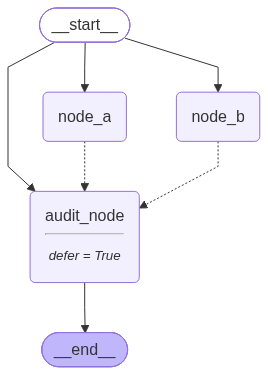

In [11]:
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from rich import print as rprint
from typing import TypedDict
from IPython.display import display
from loguru import logger

load_dotenv(override=True)

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = deepseek_model.invoke([HumanMessage(content=f"写一首关于{state['topic']}的七言绝句。")]).content
    return {
        "poem": poem,
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = deepseek_model.invoke([HumanMessage(content=f"写一个关于{state['topic']}的笑话。")]).content
    return {
        "joke": joke,
    }

def audit_node(state: OverAllState) -> OverAllState:
    logger.info(f"任务节点全部执行完毕，诗{'已生成' if state['poem'] else '未生成'}，笑话{'已生成' if state['joke'] else '未生成'}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("audit_node", audit_node, defer=True)

builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge(START, "audit_node")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("audit_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "布偶狗"})
rprint(res)
display(graph)
